# BDD100K — alvaromalfaro Dataset Analysis

Analysis of the [BDD100K alvaromalfaro Kaggle dataset](https://www.kaggle.com/datasets/alvaromalfaro/bdd100k).  
One JSON file per image; each file contains detection boxes (`box2d`) **and** drivable/lane polygons (`poly2d`).

Sections:
1. Setup & Paths
2. Structure Overview
3. Load Labels
4. Class Distribution (detection)
5. Area & Lane Category Analysis
6. Scene Attributes
7. BBox Statistics
8. Visualizations — 7-column combined (original · det overlay · det bg · drivable overlay · drivable colormap · lane overlay · lane colormap)
9. Label Format Note

## 1. Setup & Paths

In [1]:
from pathlib import Path
import json
import random
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Polygon as MplPolygon
from PIL import Image

# Find repo root
ROOT = Path(".").resolve()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

DATASET_ROOT = ROOT / "data" / "raw" / "bdd100k_alvaromalfaro" / "bdd100k"
IMG_ROOT     = DATASET_ROOT / "images" / "100k"
LABEL_ROOT   = DATASET_ROOT / "labels"
PROC_ROOT    = ROOT / "data" / "processed" / "bdd100k_frames"

for p in [DATASET_ROOT, IMG_ROOT, LABEL_ROOT]:
    status = "OK" if p.exists() else "MISSING"
    print(f"[{status}]  {p.relative_to(ROOT)}")
proc_status = "OK" if PROC_ROOT.exists() else "not yet generated"
print(f"[{proc_status}]  {PROC_ROOT.relative_to(ROOT)}")

[OK]  data/raw/bdd100k_alvaromalfaro/bdd100k
[OK]  data/raw/bdd100k_alvaromalfaro/bdd100k/images/100k
[OK]  data/raw/bdd100k_alvaromalfaro/bdd100k/labels
[OK]  data/processed/bdd100k_frames


## 2. Structure Overview

In [2]:
splits = ("train", "val", "test")
img_counts, label_counts = {}, {}
for split in splits:
    img_counts[split]   = len(list((IMG_ROOT   / split).glob("*.jpg")))
    label_counts[split] = len(list((LABEL_ROOT / split).glob("*.json")))

print(f"{'Split':<8}  {'Images':>8}  {'Label JSONs':>12}")
print("-" * 35)
for split in splits:
    print(f"{split:<8}  {img_counts[split]:>8,}  {label_counts[split]:>12,}")
print("-" * 35)
print(f"{'TOTAL':<8}  {sum(img_counts.values()):>8,}  {sum(label_counts.values()):>12,}")

print("\nSample filenames:")
for split in ("train", "val"):
    samples = sorted((IMG_ROOT / split).glob("*.jpg"))[:3]
    print(f"  images/100k/{split}/  ({img_counts[split]:,} files)")
    for s in samples:
        print(f"    {s.name}")

Split       Images   Label JSONs
-----------------------------------
train       70,000        70,000
val         10,000        10,000
test        20,000        20,000
-----------------------------------
TOTAL      100,000       100,000

Sample filenames:
  images/100k/train/  (70,000 files)
    0000f77c-6257be58.jpg
    0000f77c-62c2a288.jpg
    0000f77c-cb820c98.jpg
  images/100k/val/  (10,000 files)
    b1c66a42-6f7d68ca.jpg
    b1c81faa-3df17267.jpg
    b1c81faa-c80764c5.jpg


## 3. Load Labels

Load all train label JSONs and display the **complete contents** of one frame.

In [3]:
train_label_files = sorted((LABEL_ROOT / "train").glob("*.json"))
val_label_files   = sorted((LABEL_ROOT / "val").glob("*.json"))

print(f"Loading {len(train_label_files):,} train label JSONs...")
t0 = time.time()
train_labels = [json.loads(p.read_text()) for p in train_label_files]
elapsed = time.time() - t0
print(f"Loaded {len(train_labels):,} frames in {elapsed:.1f}s")

print(f"\nLoading {len(val_label_files):,} val label JSONs...")
val_labels = [json.loads(p.read_text()) for p in val_label_files]
print(f"Loaded {len(val_labels):,} val frames")

# ── Full frame dump ──────────────────────────────────────────────────────
print("\n" + "=" * 62)
print("FULL FRAME INFO — train_labels[0]")
print("=" * 62)

sample = train_labels[0]
print(f"\ntop-level keys : {list(sample.keys())}")
print(f"name           : {sample['name']}")
print(f"attributes     :")
for k, v in sample.get("attributes", {}).items():
    print(f"  {k}: {v}")
print(f"frames         : list of {len(sample['frames'])} frame(s)")

frame = sample["frames"][0]
print(f"\nframes[0] keys : {list(frame.keys())}")
print(f"timestamp      : {frame.get('timestamp')}")

objs      = frame["objects"]
box_objs  = [o for o in objs if "box2d"  in o]
poly_objs = [o for o in objs if "poly2d" in o]
area_objs = [o for o in poly_objs if o.get("category", "").startswith("area/")]
lane_objs = [o for o in poly_objs if o.get("category", "").startswith("lane/")]
print(f"\nobjects total  : {len(objs)}")
print(f"  box2d  (det) : {len(box_objs)}")
print(f"  poly2d total : {len(poly_objs)}  (area/: {len(area_objs)}, lane/: {len(lane_objs)})")

print("\n── All objects in this frame ───────────────────────────────────────────")
print(f"  {'#':<4} {'type':<8} {'category':<26} {'details'}")
print(f"  {'-'*4} {'-'*8} {'-'*26} {'-'*38}")
for i, obj in enumerate(objs):
    ann = "box2d" if "box2d" in obj else "poly2d" if "poly2d" in obj else "other"
    cat = obj.get("category", "?")
    if ann == "box2d":
        b = obj["box2d"]
        detail = f"x1={b['x1']:.0f} y1={b['y1']:.0f} x2={b['x2']:.0f} y2={b['y2']:.0f}"
    elif ann == "poly2d":
        detail = f"{len(obj['poly2d'])} vertices"
    else:
        detail = ""
    obj_attrs = {k: v for k, v in obj.get("attributes", {}).items() if v is not False}
    attr_s = f"  {obj_attrs}" if obj_attrs else ""
    print(f"  {i:<4} {ann:<8} {cat:<26} {detail}{attr_s}")

print("\n── First box2d object (full JSON) ──────────────────────────────────────")
if box_objs:
    print(json.dumps(box_objs[0], indent=2))

print("\n── First area/ object (full JSON, poly2d capped at 4 verts) ───────────")
if area_objs:
    obj = area_objs[0]
    n = len(obj["poly2d"])
    truncated = {**obj, "poly2d": obj["poly2d"][:4] + ([f"... {n} verts total"] if n > 4 else [])}
    print(json.dumps(truncated, indent=2))

print("\n── First lane/ object (full JSON, poly2d capped at 4 verts) ───────────")
if lane_objs:
    obj = lane_objs[0]
    n = len(obj["poly2d"])
    truncated = {**obj, "poly2d": obj["poly2d"][:4] + ([f"... {n} verts total"] if n > 4 else [])}
    print(json.dumps(truncated, indent=2))

Loading 70,000 train label JSONs...
Loaded 70,000 frames in 43.2s

Loading 10,000 val label JSONs...
Loaded 10,000 val frames

FULL FRAME INFO — train_labels[0]

top-level keys : ['name', 'frames', 'attributes']
name           : 0000f77c-6257be58
attributes     :
  weather: clear
  scene: city street
  timeofday: daytime
frames         : list of 1 frame(s)

frames[0] keys : ['timestamp', 'objects']
timestamp      : 10000

objects total  : 11
  box2d  (det) : 7
  poly2d total : 4  (area/: 1, lane/: 3)

── All objects in this frame ───────────────────────────────────────────
  #    type     category                   details
  ---- -------- -------------------------- --------------------------------------
  0    box2d    traffic light              x1=1126 y1=133 x2=1157 y2=211  {'trafficLightColor': 'green'}
  1    box2d    traffic light              x1=1157 y1=137 x2=1192 y2=211  {'trafficLightColor': 'green'}
  2    box2d    traffic sign               x1=1102 y1=211 x2=1171 y2=234  {'t

## 4. Class Distribution (detection)

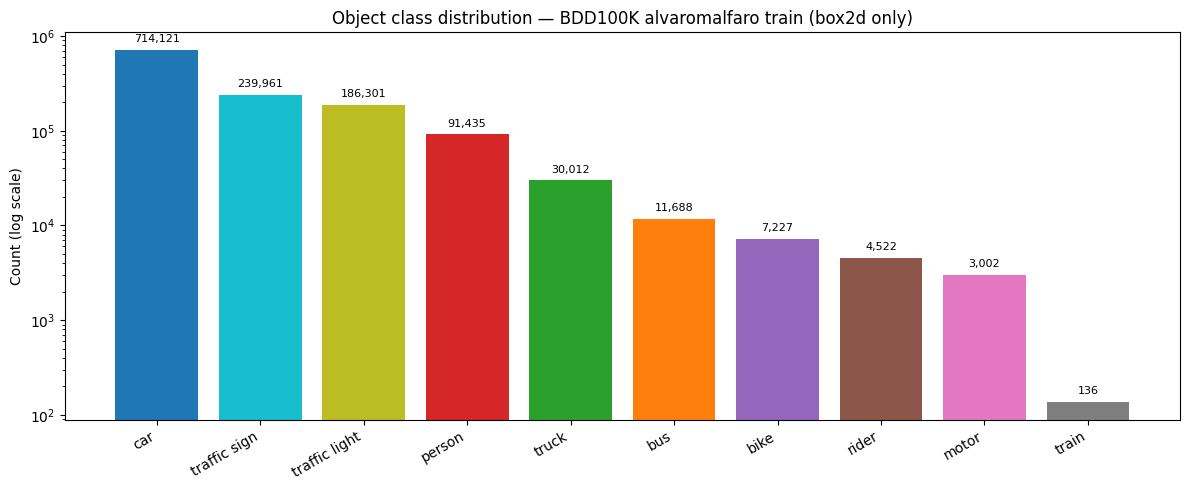

Category counts:
  car                   714,121
  traffic sign          239,961
  traffic light         186,301
  person                 91,435
  truck                  30,012
  bus                    11,688
  bike                    7,227
  rider                   4,522
  motor                   3,002
  train                     136


In [4]:
CLASS_COLORS = {
    "car":           "#1f77b4",
    "person":        "#d62728",
    "truck":         "#2ca02c",
    "bus":           "#ff7f0e",
    "bike":          "#9467bd",
    "rider":         "#8c564b",
    "motor":         "#e377c2",
    "traffic light": "#bcbd22",
    "traffic sign":  "#17becf",
    "train":         "#7f7f7f",
}
ALV_TO_CANONICAL = {"pedestrian": "person", "bicycle": "bike", "motorcycle": "motor"}

cat_counter = Counter()
for frame in train_labels:
    for obj in frame["frames"][0]["objects"]:
        if "box2d" in obj:
            cat = ALV_TO_CANONICAL.get(obj["category"], obj["category"])
            cat_counter[cat] += 1

sorted_cats = sorted(cat_counter.items(), key=lambda x: -x[1])
cats, counts = zip(*sorted_cats)
colors = [CLASS_COLORS.get(c, "#aaaaaa") for c in cats]

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(cats, counts, color=colors)
ax.set_yscale("log")
ax.set_ylabel("Count (log scale)")
ax.set_title("Object class distribution — BDD100K alvaromalfaro train (box2d only)")
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.15,
            f"{count:,}", ha="center", va="bottom", fontsize=8)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print("Category counts:")
for cat, count in sorted_cats:
    print(f"  {cat:<20} {count:>8,}")

## 5. Area & Lane Category Analysis

Count all `area/` and `lane/` polygon annotations across the train split.

Area categories (poly2d):
  area/drivable                    64,050
  area/alternative                 61,799
  area/unknown                          2

Lane categories (poly2d):
  lane/single white               247,108
  lane/road curb                  109,868
  lane/crosswalk                  108,284
  lane/double yellow               37,519
  lane/single yellow               20,220
  lane/double white                 5,674
  lane/single other                   249
  lane/double other                    26

Frames with >=1 area/ annotation : 66,921 / 70,000  (95.6%)
Frames with >=1 lane/ annotation : 66,640 / 70,000  (95.2%)


/tmp/ipykernel_438986/3819415375.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(cats_a, rotation=20, ha="right")
/tmp/ipykernel_438986/3819415375.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(cats_l, rotation=30, ha="right")


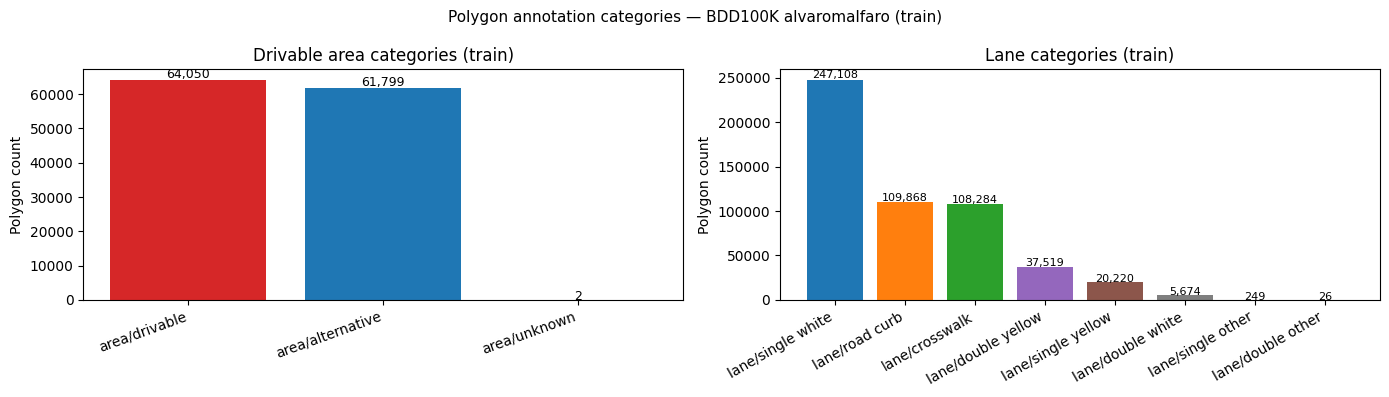

In [5]:
area_counter = Counter()
lane_counter = Counter()

for frame in train_labels:
    for obj in frame["frames"][0]["objects"]:
        if "poly2d" not in obj:
            continue
        cat = obj.get("category", "")
        if cat.startswith("area/"):
            area_counter[cat] += 1
        elif cat.startswith("lane/"):
            lane_counter[cat] += 1

print("Area categories (poly2d):")
for cat, cnt in sorted(area_counter.items(), key=lambda x: -x[1]):
    print(f"  {cat:<30} {cnt:>8,}")

print("\nLane categories (poly2d):")
for cat, cnt in sorted(lane_counter.items(), key=lambda x: -x[1]):
    print(f"  {cat:<30} {cnt:>8,}")

frames_with_area = sum(
    1 for f in train_labels
    if any(o.get("category", "").startswith("area/") and "poly2d" in o
           for o in f["frames"][0]["objects"])
)
frames_with_lane = sum(
    1 for f in train_labels
    if any(o.get("category", "").startswith("lane/") and "poly2d" in o
           for o in f["frames"][0]["objects"])
)
n = len(train_labels)
print(f"\nFrames with >=1 area/ annotation : {frames_with_area:,} / {n:,}  ({100*frames_with_area/n:.1f}%)")
print(f"Frames with >=1 lane/ annotation : {frames_with_lane:,} / {n:,}  ({100*frames_with_lane/n:.1f}%)")

# Charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

cats_a = sorted(area_counter, key=lambda x: -area_counter[x])
ax1.bar(cats_a, [area_counter[c] for c in cats_a], color=["#d62728", "#1f77b4"][:len(cats_a)])
ax1.set_title("Drivable area categories (train)")
ax1.set_ylabel("Polygon count")
ax1.set_xticklabels(cats_a, rotation=20, ha="right")
for i, cat in enumerate(cats_a):
    ax1.text(i, area_counter[cat] * 1.01, f"{area_counter[cat]:,}", ha="center", fontsize=9)

cats_l = sorted(lane_counter, key=lambda x: -lane_counter[x])
colors_l = plt.cm.tab10(np.linspace(0, 1, len(cats_l)))
ax2.bar(cats_l, [lane_counter[c] for c in cats_l], color=colors_l)
ax2.set_title("Lane categories (train)")
ax2.set_ylabel("Polygon count")
ax2.set_xticklabels(cats_l, rotation=30, ha="right")
for i, cat in enumerate(cats_l):
    ax2.text(i, lane_counter[cat] * 1.01, f"{lane_counter[cat]:,}", ha="center", fontsize=8)

plt.suptitle("Polygon annotation categories — BDD100K alvaromalfaro (train)", fontsize=11)
plt.tight_layout()
plt.show()

## 6. Scene Attributes

Train frames with non-empty attributes : 70,000
Train frames with empty   attributes   : 0
Coverage: 100.0%


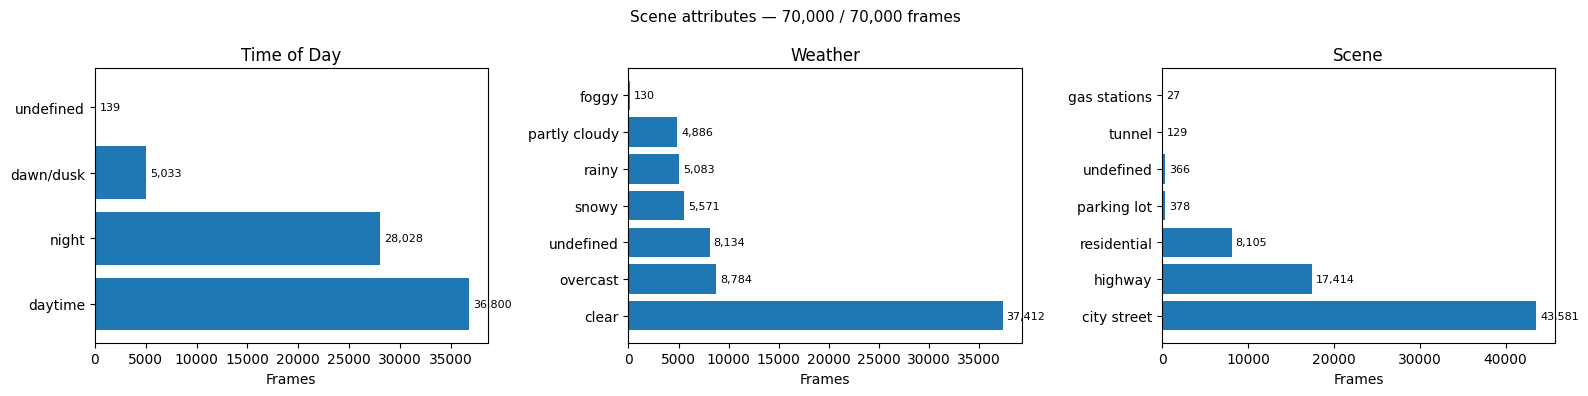

In [6]:
frames_with_attrs = [f for f in train_labels if f.get("attributes")]
frames_without    = len(train_labels) - len(frames_with_attrs)
print(f"Train frames with non-empty attributes : {len(frames_with_attrs):,}")
print(f"Train frames with empty   attributes   : {frames_without:,}")
print(f"Coverage: {100 * len(frames_with_attrs) / len(train_labels):.1f}%")

if frames_with_attrs:
    tod_counter     = Counter()
    weather_counter = Counter()
    scene_counter   = Counter()
    for frame in frames_with_attrs:
        attrs = frame["attributes"]
        tod_counter[attrs.get("timeofday", "unknown")] += 1
        weather_counter[attrs.get("weather", "unknown")] += 1
        scene_counter[attrs.get("scene", "unknown")] += 1

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, (counter, title) in zip(axes, [
        (tod_counter,     "Time of Day"),
        (weather_counter, "Weather"),
        (scene_counter,   "Scene"),
    ]):
        lbls = sorted(counter, key=lambda k: -counter[k])
        vals = [counter[k] for k in lbls]
        ax.barh(lbls, vals)
        ax.set_title(title)
        ax.set_xlabel("Frames")
        for i, v in enumerate(vals):
            ax.text(v + max(vals) * 0.01, i, f"{v:,}", va="center", fontsize=8)
    plt.suptitle(f"Scene attributes — {len(frames_with_attrs):,} / {len(train_labels):,} frames", fontsize=11)
    plt.tight_layout()
    plt.show()

## 7. BBox Statistics

Total bbox annotations (train): 1,288,010
Width  — mean=56.6  median=28.7  std=75.8
Height — mean=49.9  median=29.1  std=61.7
Aspect — mean=1.22  median=1.10
Boxes/image — mean=18.4  max=91


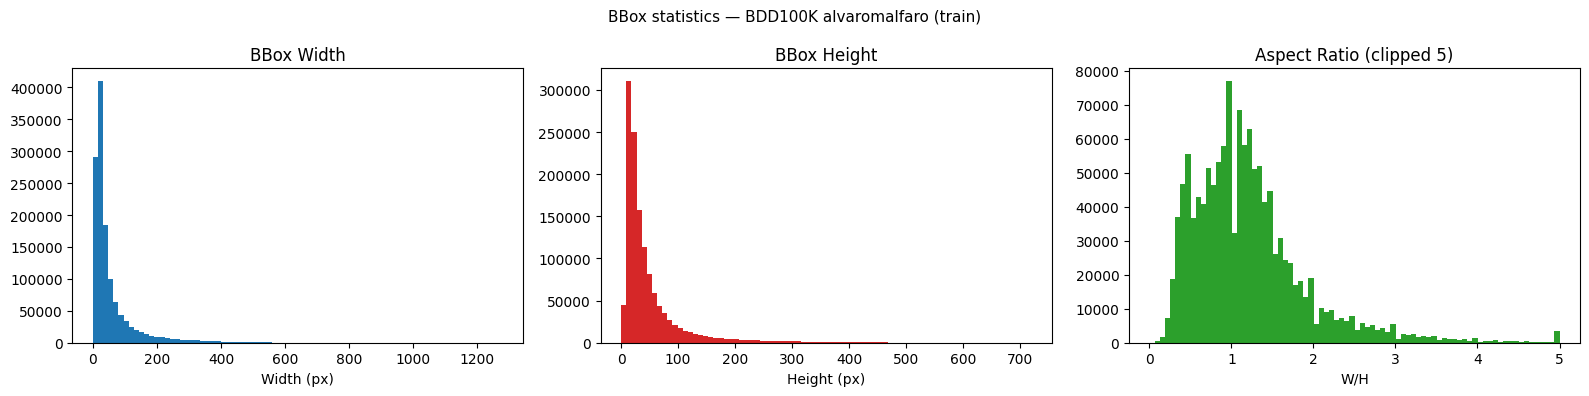

In [7]:
widths, heights, aspects, n_per_image = [], [], [], []
for frame in train_labels:
    n = 0
    for obj in frame["frames"][0]["objects"]:
        b = obj.get("box2d")
        if b is None:
            continue
        w, h = b["x2"] - b["x1"], b["y2"] - b["y1"]
        if w > 0 and h > 0:
            widths.append(w); heights.append(h); aspects.append(w / h); n += 1
    n_per_image.append(n)

widths  = np.array(widths)
heights = np.array(heights)
aspects = np.array(aspects)
print(f"Total bbox annotations (train): {len(widths):,}")
print(f"Width  — mean={widths.mean():.1f}  median={np.median(widths):.1f}  std={widths.std():.1f}")
print(f"Height — mean={heights.mean():.1f}  median={np.median(heights):.1f}  std={heights.std():.1f}")
print(f"Aspect — mean={aspects.mean():.2f}  median={np.median(aspects):.2f}")
print(f"Boxes/image — mean={np.mean(n_per_image):.1f}  max={max(n_per_image)}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(widths,  bins=80, color="#1f77b4", edgecolor="none")
axes[0].set_title("BBox Width"); axes[0].set_xlabel("Width (px)")
axes[1].hist(heights, bins=80, color="#d62728", edgecolor="none")
axes[1].set_title("BBox Height"); axes[1].set_xlabel("Height (px)")
axes[2].hist(np.clip(aspects, 0, 5), bins=80, color="#2ca02c", edgecolor="none")
axes[2].set_title("Aspect Ratio (clipped 5)"); axes[2].set_xlabel("W/H")
plt.suptitle("BBox statistics — BDD100K alvaromalfaro (train)", fontsize=11)
plt.tight_layout(); plt.show()

## 8. Visualizations

One combined figure per row (frame). **7 columns**:

| Col | Content |
|---|---|
| 1 | Original image |
| 2 | Detection overlay (bboxes at α=0.3 + class labels) |
| 3 | Detection ground-truth (filled bboxes on black bg) |
| 4 | Drivable overlay (area polygons at α=0.3) |
| 5 | Drivable colormap (red=direct, blue=alt) |
| 6 | Lane overlay (lane polygons at α=0.3) |
| 7 | Lane colormap (per-category colours on black bg) |

Only frames that contain all three annotation types are eligible for sampling.

In [8]:
# ── Palette definitions ──────────────────────────────────────────────────
CLASS_COLORS = {
    "car":           "#1f77b4",
    "person":        "#d62728",
    "truck":         "#2ca02c",
    "bus":           "#ff7f0e",
    "bike":          "#9467bd",
    "rider":         "#8c564b",
    "motor":         "#e377c2",
    "traffic light": "#bcbd22",
    "traffic sign":  "#17becf",
    "train":         "#7f7f7f",
}
ALV_TO_CANONICAL = {"pedestrian": "person", "bicycle": "bike", "motorcycle": "motor"}

DRIVABLE_COLORS = {
    "area/drivable":    "#ff0000",
    "area/alternative": "#0000ff",
}

LANE_COLORS = {
    "lane/single white":  "#ffffff",
    "lane/single yellow": "#ffff00",
    "lane/double white":  "#aaaaff",
    "lane/double yellow": "#ffaa00",
    "lane/road curb":     "#00cc44",
    "lane/crosswalk":     "#ff44ff",
    "lane/single other":  "#888888",
    "lane/double other":  "#555555",
}

# ── Helper functions ──────────────────────────────────────────────────────
def get_image(frame, split="train"):
    p = IMG_ROOT / split / (frame["name"] + ".jpg")
    return np.array(Image.open(p).convert("RGB")) if p.exists() else None

def get_boxes(frame):
    result = []
    for obj in frame["frames"][0]["objects"]:
        if "box2d" in obj:
            cat = ALV_TO_CANONICAL.get(obj["category"], obj["category"])
            result.append((cat, obj["box2d"]))
    return result

def get_drivable_polys(frame):
    return [o for o in frame["frames"][0]["objects"]
            if "poly2d" in o and o.get("category", "").startswith("area/")]

def get_lane_polys(frame):
    return [o for o in frame["frames"][0]["objects"]
            if "poly2d" in o and o.get("category", "").startswith("lane/")]

def draw_poly(ax, poly2d, color, alpha, min_verts=3):
    verts = [[p[0], p[1]] for p in poly2d]
    if len(verts) >= min_verts:
        ax.add_patch(MplPolygon(verts, closed=True,
                                facecolor=color, edgecolor=color, alpha=alpha))
    elif len(verts) == 2:
        ax.plot([verts[0][0], verts[1][0]], [verts[0][1], verts[1][1]],
                color=color, linewidth=1.5, alpha=alpha)

print("Helpers ready.")

Helpers ready.


Candidate frames (all three annotation types): 64,218
  7481b347-18b6baee
  14a48327-1c78004c
  04c20a03-45983f59
  871e1754-5868f89c
  3207d01f-7b0a913c
  2c730c48-9f638991


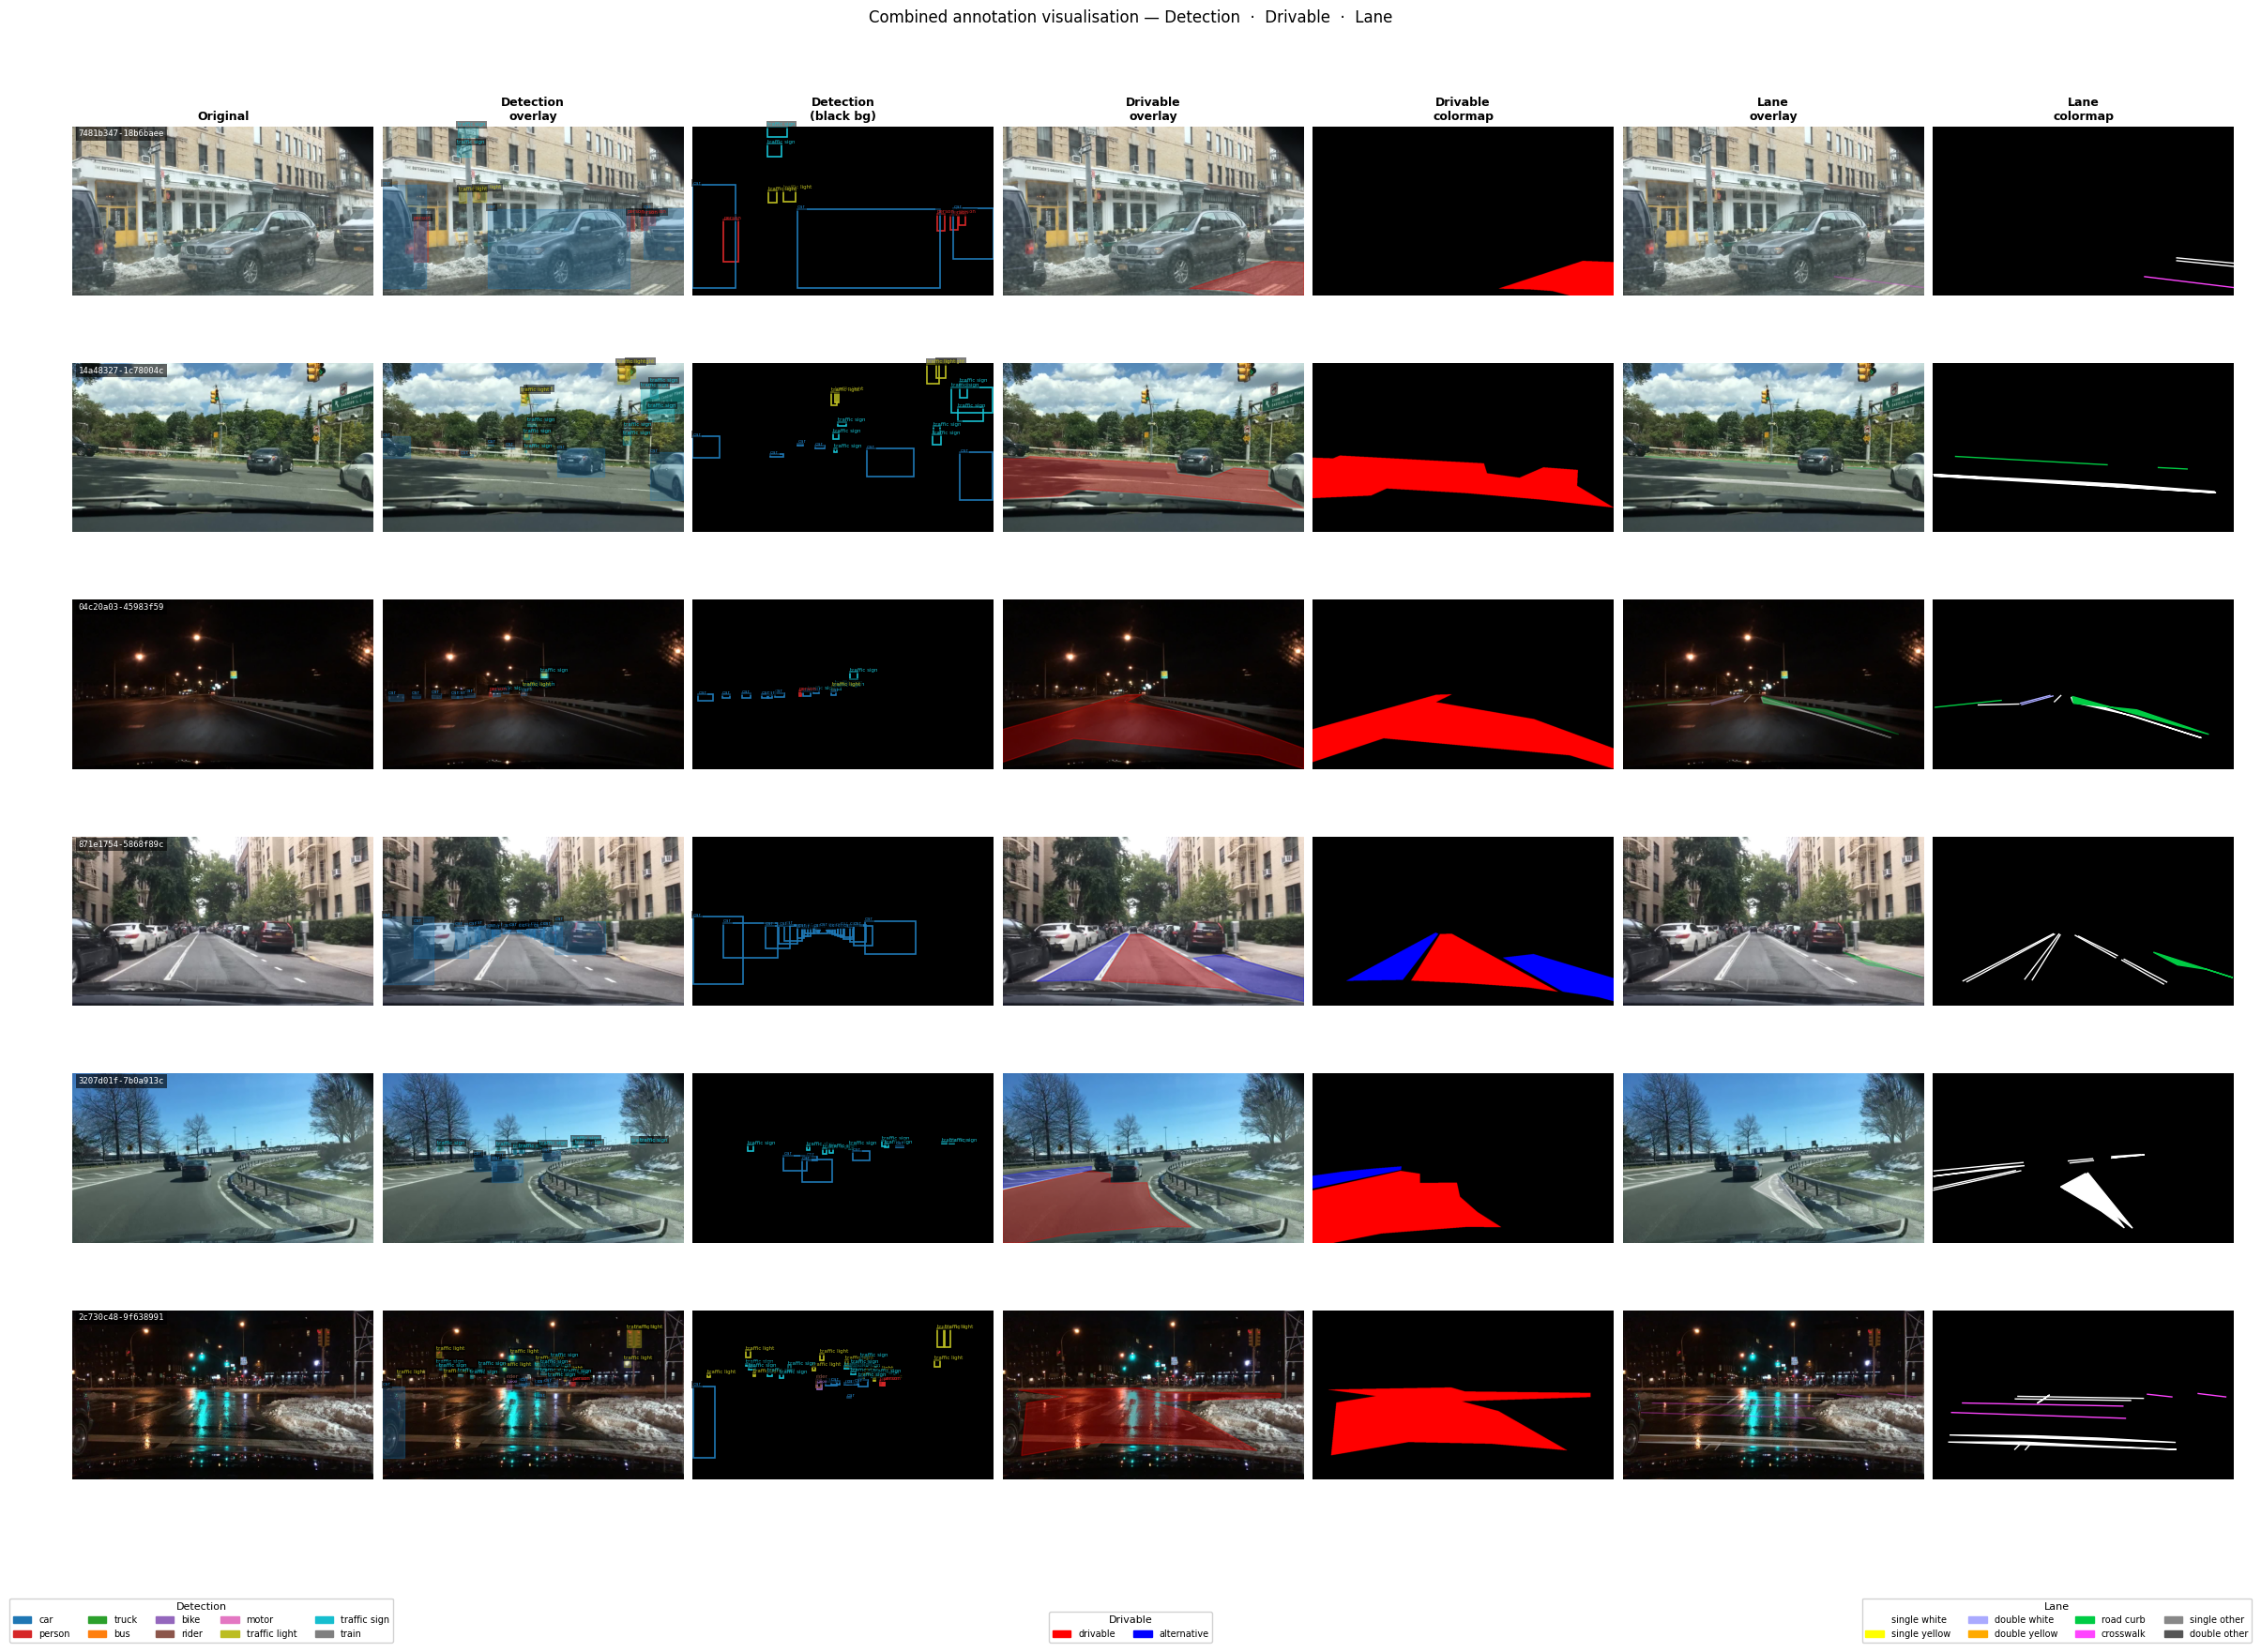

In [12]:
N_SAMPLES = 6

random.seed(42)
candidates = [
    f for f in train_labels
    if get_boxes(f) and get_drivable_polys(f) and get_lane_polys(f)
]

sample_frames = random.sample(candidates, N_SAMPLES)

print(f"Candidate frames (all three annotation types): {len(candidates):,}")
for f in sample_frames:
    print(f"  {f['name']}")

PROC_CMAP_DIR = PROC_ROOT / "drivable" / "colormaps" / "train"

COL_TITLES = [
    "Original",
    "Detection\noverlay",
    "Detection\n(black bg)",
    "Drivable\noverlay",
    "Drivable\ncolormap",
    "Lane\noverlay",
    "Lane\ncolormap",
]

fig, axes = plt.subplots(
    N_SAMPLES, 7,
    figsize=(24, 3.0 * N_SAMPLES),
    gridspec_kw={"hspace": 0.18, "wspace": 0.03}
)

# In case N_SAMPLES = 1 in future
axes = np.atleast_2d(axes)

for col_idx, title in enumerate(COL_TITLES):
    axes[0, col_idx].set_title(title, fontsize=9, fontweight="bold", pad=5)

for row, frame in enumerate(sample_frames):
    img   = get_image(frame)
    boxes = get_boxes(frame)
    driv  = get_drivable_polys(frame)
    lanes = get_lane_polys(frame)
    stem  = frame["name"]

    # Show frame ID inside the Original image
    axes[row, 0].text(
        0.02, 0.98, stem,
        transform=axes[row, 0].transAxes,
        ha="left", va="top",
        fontsize=6.5,
        fontfamily="monospace",
        color="white",
        bbox=dict(facecolor="black", alpha=0.6, pad=2, linewidth=0)
    )

    if img is None:
        for c in range(7):
            axes[row, c].text(
                0.5, 0.5, "not found",
                ha="center", va="center",
                transform=axes[row, c].transAxes,
                fontsize=6
            )
            axes[row, c].axis("off")
        continue

    # Col 0: Original
    axes[row, 0].imshow(img)
    axes[row, 0].axis("off")

    # Col 1: Detection overlay
    axes[row, 1].imshow(img)
    for cat, b in boxes:
        col = CLASS_COLORS.get(cat, "#ffffff")
        axes[row, 1].add_patch(mpatches.Rectangle(
            (b["x1"], b["y1"]),
            b["x2"] - b["x1"],
            b["y2"] - b["y1"],
            linewidth=1.0,
            edgecolor=col,
            facecolor=col,
            alpha=0.3
        ))
        axes[row, 1].text(
            b["x1"], b["y1"] - 2, cat,
            color=col, fontsize=4,
            bbox=dict(facecolor="black", alpha=0.5, pad=1, linewidth=0)
        )
    axes[row, 1].axis("off")

    # Col 2: Detection on black background (outline only)
    axes[row, 2].imshow(np.zeros_like(img))
    for cat, b in boxes:
        col = CLASS_COLORS.get(cat, "#ffffff")
        axes[row, 2].add_patch(mpatches.Rectangle(
            (b["x1"], b["y1"]),
            b["x2"] - b["x1"],
            b["y2"] - b["y1"],
            linewidth=1.2,
            edgecolor=col,
            facecolor="none"
        ))
        axes[row, 2].text(
            b["x1"], b["y1"] - 2, cat,
            color=col, fontsize=4,
            bbox=dict(facecolor="black", alpha=0.5, pad=1, linewidth=0)
        )
    axes[row, 2].axis("off")

    # Col 3: Drivable overlay
    axes[row, 3].imshow(img)
    for obj in driv:
        col = DRIVABLE_COLORS.get(obj["category"], "#ffffff")
        draw_poly(axes[row, 3], obj["poly2d"], col, alpha=0.3)
    axes[row, 3].axis("off")

    # Col 4: Drivable colormap
    cmap_path = PROC_CMAP_DIR / f"{stem}.png"
    if cmap_path.exists():
        axes[row, 4].imshow(np.array(Image.open(cmap_path).convert("RGB")))
    else:
        axes[row, 4].imshow(np.zeros_like(img))
        for cat_order in ("area/alternative", "area/drivable"):
            col = DRIVABLE_COLORS[cat_order]
            for obj in driv:
                if obj["category"] == cat_order:
                    draw_poly(axes[row, 4], obj["poly2d"], col, alpha=1.0)
    axes[row, 4].axis("off")

    # Col 5: Lane overlay
    axes[row, 5].imshow(img)
    for obj in lanes:
        col = LANE_COLORS.get(obj["category"], "#cccccc")
        draw_poly(axes[row, 5], obj["poly2d"], col, alpha=0.3, min_verts=2)
    axes[row, 5].axis("off")

    # Col 6: Lane colormap on black background
    axes[row, 6].imshow(np.zeros_like(img))
    for obj in lanes:
        col = LANE_COLORS.get(obj["category"], "#cccccc")
        draw_poly(axes[row, 6], obj["poly2d"], col, alpha=1.0, min_verts=2)
    axes[row, 6].axis("off")


# Legends
det_patches = [
    mpatches.Patch(color=c, label=cls)
    for cls, c in CLASS_COLORS.items()
]

driv_patches = [
    mpatches.Patch(color=c, label=cat.split("/")[1])
    for cat, c in DRIVABLE_COLORS.items()
]

lane_patches = [
    mpatches.Patch(color=c, label=cat.split("/")[1])
    for cat, c in LANE_COLORS.items()
    if lane_counter.get(cat, 0) > 0
]

fig.legend(
    handles=det_patches, title="Detection",
    loc="lower left", ncol=5,
    fontsize=7, title_fontsize=8,
    framealpha=0.9, bbox_to_anchor=(0.0, 0.01)
)

fig.legend(
    handles=driv_patches, title="Drivable",
    loc="lower center", ncol=2,
    fontsize=7, title_fontsize=8,
    framealpha=0.9, bbox_to_anchor=(0.5, 0.01)
)

fig.legend(
    handles=lane_patches, title="Lane",
    loc="lower right", ncol=4,
    fontsize=7, title_fontsize=8,
    framealpha=0.9, bbox_to_anchor=(1.0, 0.01)
)

fig.suptitle(
    "Combined annotation visualisation — Detection  ·  Drivable  ·  Lane",
    fontsize=12, y=0.98
)

# Use subplots_adjust instead of tight_layout
fig.subplots_adjust(left=0.03, right=0.99, top=0.92, bottom=0.10)

plt.show()

## 9. Label Format Note

| Property | alvaromalfaro |
|---|---|
| Files | One `.json` per image |
| Object list key | `frames[0]["objects"]` |
| Image name | `name` field — **no `.jpg`** extension |
| Detection annotation | `box2d: {x1, y1, x2, y2}` |
| Polygon annotation | `poly2d: [[x, y, "L"\|"C"], ...]` |
| Drivable categories | `area/drivable`, `area/alternative` |
| Lane categories | `lane/single white`, `lane/road curb`, … |
| Scene attributes | top-level `attributes` (`weather`, `scene`, `timeofday`) |

In [10]:
# Confirm per-object attribute keys across all objects in train[0]
frame_obj = train_labels[0]["frames"][0]["objects"]
print("Object-level attribute keys seen in train[0]:")
for obj in frame_obj:
    obj_attrs = list(obj.get("attributes", {}).keys())
    if obj_attrs:
        print(f"  category={obj['category']:<22}  attr_keys={obj_attrs}")

Object-level attribute keys seen in train[0]:
  category=traffic light           attr_keys=['occluded', 'truncated', 'trafficLightColor']
  category=traffic light           attr_keys=['occluded', 'truncated', 'trafficLightColor']
  category=traffic sign            attr_keys=['occluded', 'truncated', 'trafficLightColor']
  category=traffic sign            attr_keys=['occluded', 'truncated', 'trafficLightColor']
  category=car                     attr_keys=['occluded', 'truncated', 'trafficLightColor']
  category=car                     attr_keys=['occluded', 'truncated', 'trafficLightColor']
  category=traffic sign            attr_keys=['occluded', 'truncated', 'trafficLightColor']
  category=lane/road curb          attr_keys=['direction', 'style']
  category=lane/road curb          attr_keys=['direction', 'style']
  category=lane/road curb          attr_keys=['direction', 'style']
